In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

calendar = pd.read_csv('../02_Data/processed/calendar_clean.csv', parse_dates=['date'], low_memory = False)
listings = pd.read_csv('../02_Data/processed/listings_clean.csv', low_memory = False)

In [5]:
print("--- Calendar Coverage ---")
print(f"Total records: {len(calendar):,}")
print(f"Distinct listings: {calendar['listing_id'].nunique():,}")
print(f"Date range: {calendar['date'].min().date()} → {calendar['date'].max().date()}")
print(f"Days covered: {calendar['date'].nunique()}")

# Coverage per listing
cov_per_listing = calendar.groupby('listing_id').size()
print(f"\nDates per listing — Median: {cov_per_listing.median()}, Min: {cov_per_listing.min()}, Max: {cov_per_listing.max()}")

# available vs unavailable
avail_counts = calendar['available'].value_counts(dropna=False)
for k, v in avail_counts.items():
    print(f"  {'Available' if k else 'Unavailable'}: {v:,} ({v/len(calendar)*100:.1f}%)")

--- Calendar Coverage ---
Total records: 5,623,190
Distinct listings: 15,406
Date range: 2026-06-24 → 2027-07-02
Days covered: 374

Dates per listing — Median: 365.0, Min: 365, Max: 365
  Available: 3,281,038 (58.3%)
  Unavailable: 2,342,152 (41.7%)


In [9]:
# monthly availability pattern
calendar['month'] = calendar['date'].dt.to_period('M')

monthly = calendar.groupby('month').agg(
    total_days = ('date', 'count'),
    avail_days = ('available', 'sum'),
    listings = ('listing_id', 'nunique')
).reset_index()

monthly['avail_pct'] = (monthly['avail_days'] / monthly['total_days'] * 100).round(1)

display(monthly)



,month,total_days,avail_days,listings,avail_pct
0,2026-06,80551,21866,13035,27.1
1,2026-07,473369,180192,15406,38.1
2,2026-08,477586,264216,15406,55.3
3,2026-09,462180,281730,15406,61.0
4,2026-10,477586,306406,15406,64.2
5,2026-11,462180,327407,15406,70.8
6,2026-12,477586,340529,15406,71.3
7,2027-01,477586,306605,15406,64.2
8,2027-02,431368,272314,15406,63.1
9,2027-03,477586,291696,15406,61.1


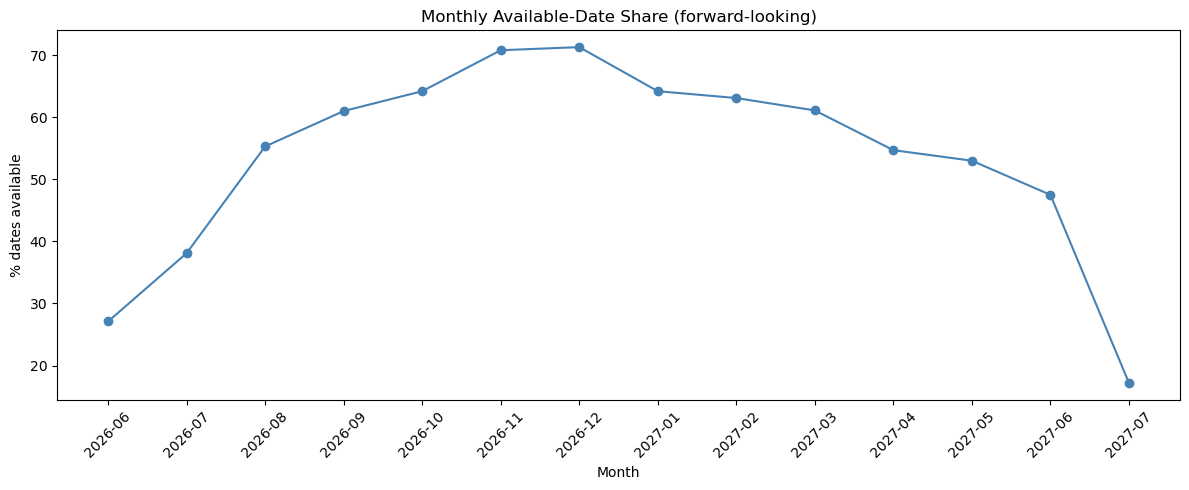

In [10]:
# charts

fig, ax = plt.subplots(figsize=(12,5))
ax.plot(monthly['month'].astype(str), monthly['avail_pct'], marker='o', color='steelblue')
ax.set_title('Monthly Available-Date Share (forward-looking)')
ax.set_ylabel('% dates available')
ax.set_xlabel('Month')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()